# Taller Final – Minería de Datos
## Segmentación de Clientes con K-Means

| | |
|---|---|
| **Autor** | Juan Felipe Mora Revelo |
| **Asignatura** | Inteligencia de Negocios y Minería de Datos |
| **Institución** | Universidad Cooperativa de Colombia |
| **Fecha** | Octubre de 2026 |

**Dataset:** Mall Customers (Kaggle), 200 clientes de un centro comercial.

**Objetivo general:** desarrollar un modelo de segmentación de clientes con K-Means, evaluarlo con el método del codo y el coeficiente de silueta, e interpretar los segmentos desde una perspectiva de negocio para apoyar decisiones de marketing.

| Parte | Contenido |
|---|---|
| 1 | Exploración de datos |
| 2 | Preprocesamiento (StandardScaler) |
| 3 | Método del codo |
| 4 | Coeficiente de silueta |
| 5 | Modelo K-Means |
| 6 | Interpretación de negocio |
| 7 | Despliegue con Streamlit (`app.py`) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

---
# Parte 1 – Exploración de Datos
### 1.1 Cargar el dataset

In [2]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={
    "Genre": "Genero",
    "Age": "Edad",
    "Annual Income (k$)": "Ingreso_Anual_k",
    "Spending Score (1-100)": "Puntaje_Gasto",
})
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head(10)

Filas: 200 | Columnas: 5


,CustomerID,Genero,Edad,Ingreso_Anual_k,Puntaje_Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
df.info()
print("\nValores nulos por columna:\n", df.isnull().sum())
print("\nRegistros duplicados:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   CustomerID       200 non-null    int64
 1   Genero           200 non-null    str  
 2   Edad             200 non-null    int64
 3   Ingreso_Anual_k  200 non-null    int64
 4   Puntaje_Gasto    200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Valores nulos por columna:
 CustomerID         0
Genero             0
Edad               0
Ingreso_Anual_k    0
Puntaje_Gasto      0
dtype: int64

Registros duplicados: 0


### 1.2 Identificar variables relevantes

| Variable | Tipo | ¿Útil para segmentar? |
|---|---|---|
| `CustomerID` | Identificador | **No** – es solo un consecutivo, no describe al cliente |
| `Genero` | Categórica | Limitada – K-Means trabaja con distancias euclidianas, no es ideal para categóricas |
| `Edad` | Numérica | Sí – describe el perfil demográfico |
| `Ingreso_Anual_k` | Numérica | **Sí** – capacidad de compra |
| `Puntaje_Gasto` | Numérica | **Sí** – comportamiento de consumo en el centro comercial |

### 1.3 Análisis descriptivo básico

In [4]:
df[["Edad", "Ingreso_Anual_k", "Puntaje_Gasto"]].describe().round(2)

,Edad,Ingreso_Anual_k,Puntaje_Gasto
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


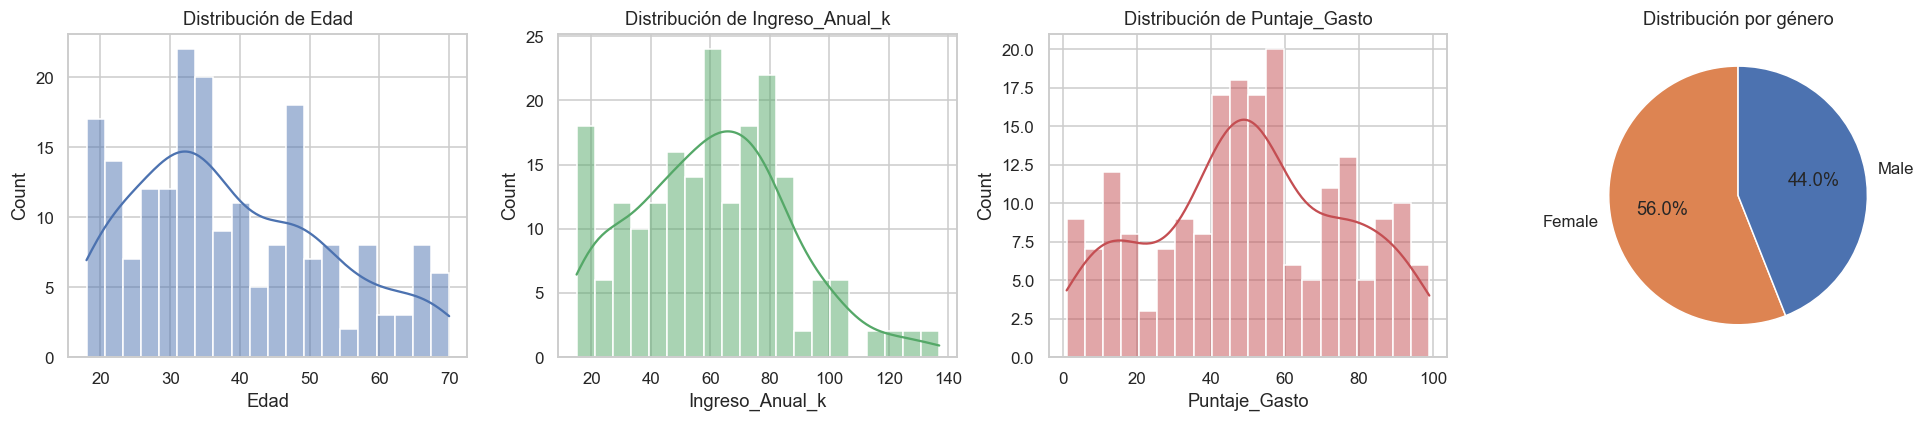

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col, color in zip(axes[:3], ["Edad", "Ingreso_Anual_k", "Puntaje_Gasto"], ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(df[col], kde=True, ax=ax, color=color, bins=20)
    ax.set_title(f"Distribución de {col}")
df["Genero"].value_counts().plot.pie(ax=axes[3], autopct="%1.1f%%", colors=["#DD8452", "#4C72B0"], startangle=90)
axes[3].set_title("Distribución por género"); axes[3].set_ylabel("")
plt.tight_layout(); plt.show()

#### Detección de valores atípicos (boxplots + regla IQR)

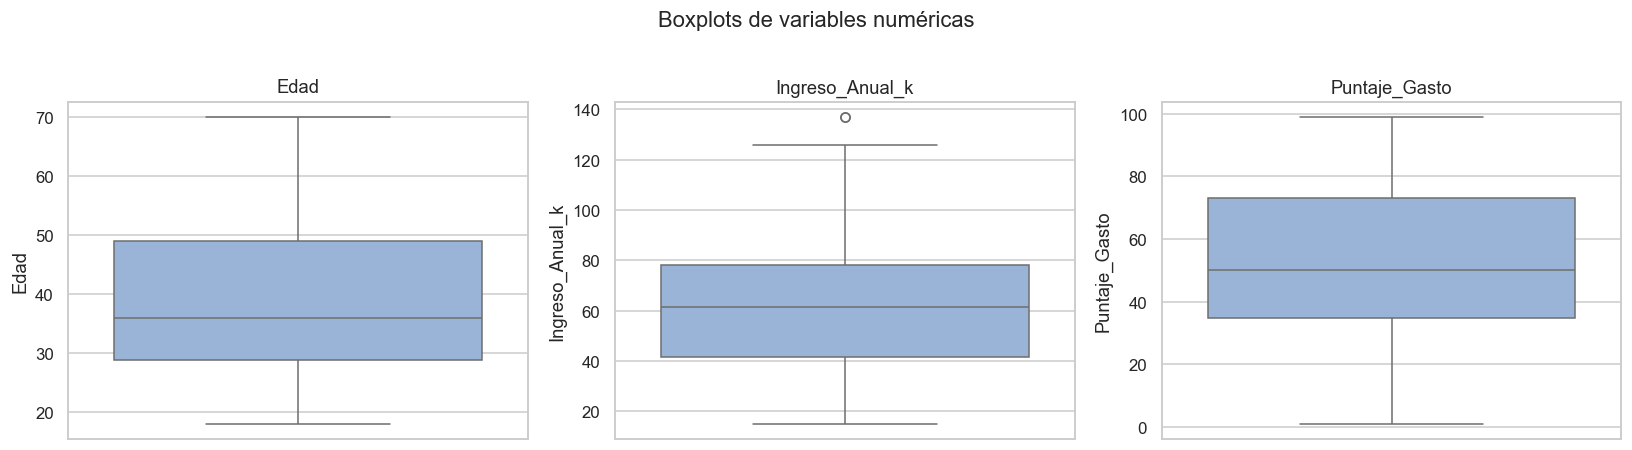

Edad             → límites [-1.6, 79.4] | atípicos: 0
Ingreso_Anual_k  → límites [-13.2, 132.8] | atípicos: 2


,CustomerID,Genero,Edad,Ingreso_Anual_k,Puntaje_Gasto
198,199,Male,32,137,18
199,200,Male,30,137,83


Puntaje_Gasto    → límites [-22.6, 130.4] | atípicos: 0


In [6]:
num_cols = ["Edad", "Ingreso_Anual_k", "Puntaje_Gasto"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#8fb3e0")
    ax.set_title(col)
plt.suptitle("Boxplots de variables numéricas", y=1.02); plt.tight_layout(); plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col:16s} → límites [{lim_inf:.1f}, {lim_sup:.1f}] | atípicos: {len(outliers)}")
    if len(outliers):
        display(outliers)

#### Relaciones entre variables

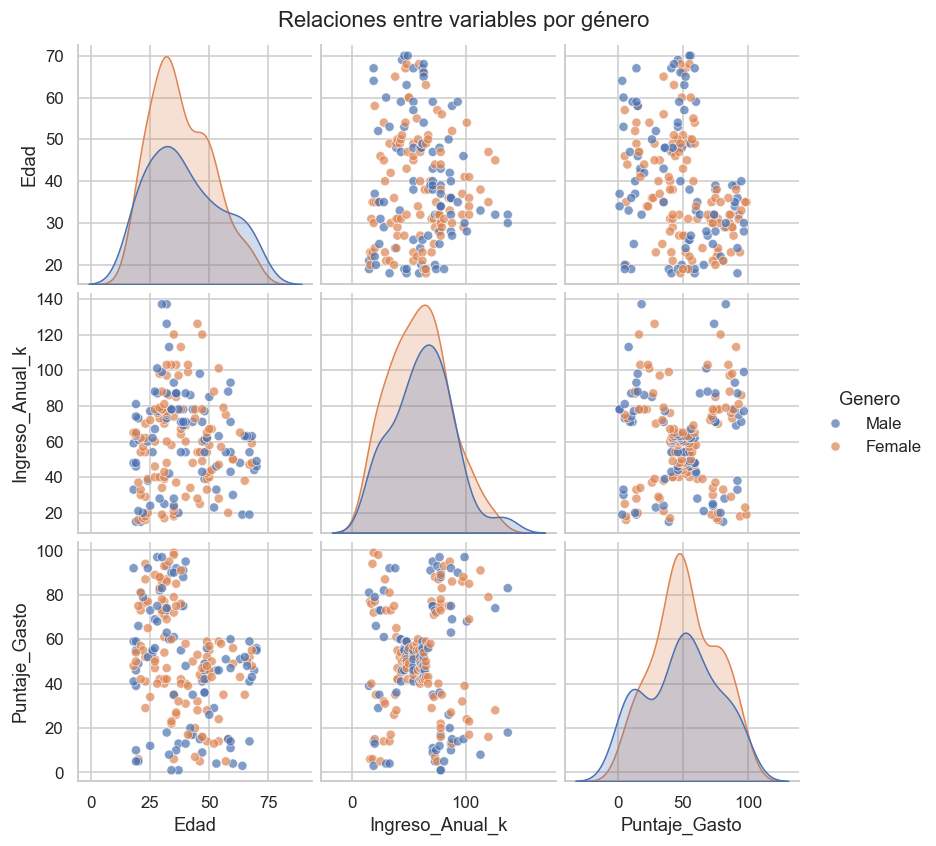

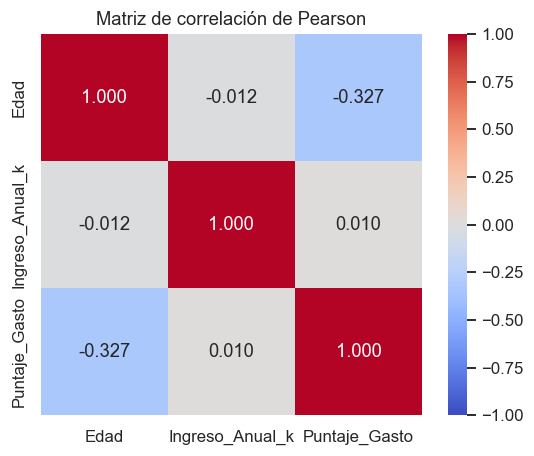

In [7]:
sns.pairplot(df, vars=num_cols, hue="Genero", diag_kind="kde", palette={"Female": "#DD8452", "Male": "#4C72B0"}, plot_kws={"alpha": .7})
plt.suptitle("Relaciones entre variables por género", y=1.02); plt.show()

plt.figure(figsize=(6, 4.5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación de Pearson"); plt.show()

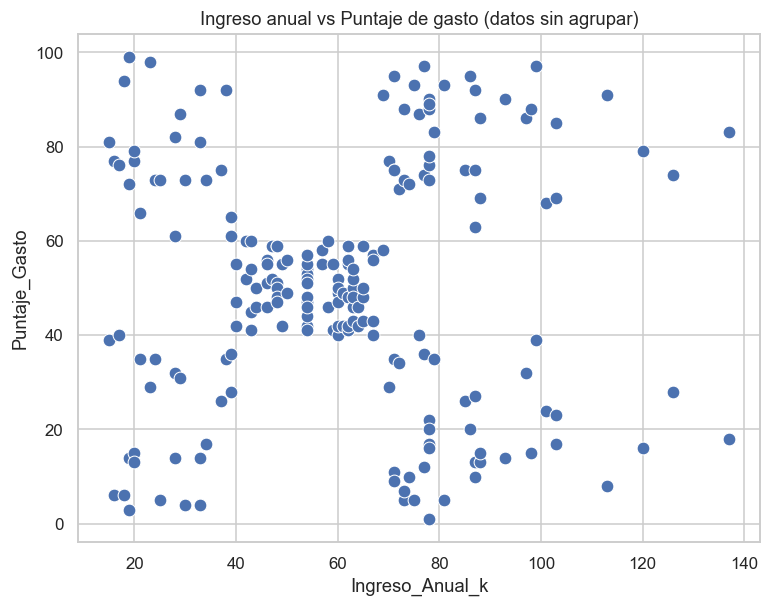

In [8]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Ingreso_Anual_k", y="Puntaje_Gasto", s=70, color="#4C72B0", edgecolor="white")
plt.title("Ingreso anual vs Puntaje de gasto (datos sin agrupar)")
plt.show()

### Preguntas – Parte 1

**❓ ¿Qué variables son más adecuadas para segmentar clientes?**

Las variables más adecuadas son **Ingreso Anual (k\$)** y **Puntaje de Gasto (1-100)**:

- Son numéricas y continuas, que es lo que necesita K-Means al calcular distancias euclidianas.
- Representan dos dimensiones clave para marketing: **cuánto puede gastar** el cliente (ingreso) y **cuánto gasta realmente** en el centro comercial (puntaje).
- En el diagrama de dispersión se ven a simple vista **cinco nubes de puntos** bien separadas, lo que anticipa una segmentación clara.

`CustomerID` se descarta porque es un identificador. `Genero` es categórica y su distribución es muy similar en ambos grupos, por lo que aporta poco a la separación. `Edad` se puede usar como variable complementaria para describir los perfiles (y la app permite explorarla en 3D), pero al incluirla en el modelo el coeficiente de silueta baja (de ≈0.55 a ≈0.43), es decir, los grupos quedan menos definidos.

**❓ ¿Se identifican valores atípicos?**

Con la regla IQR (1.5 × rango intercuartílico):

- **Edad** y **Puntaje de Gasto**: no presentan valores atípicos.
- **Ingreso Anual**: aparecen **2 registros** con ingreso de **137 k\$**, por encima del límite superior (≈132 k\$).

Estos dos valores **no son errores de digitación**: son clientes reales de ingreso muy alto y se mantienen en el análisis, porque eliminarlos haría perder información de un segmento valioso. Además, la desviación respecto al límite es pequeña y no distorsiona los centroides de forma significativa. Tampoco hay valores nulos ni registros duplicados.

**❓ ¿Qué tipo de relaciones se observan entre las variables?**

- **Ingreso vs Puntaje de Gasto:** correlación prácticamente nula (r ≈ 0.01). No hay una relación lineal, pero sí una **estructura de grupos**: el gráfico de dispersión muestra 5 agrupaciones (forma de "X" con un núcleo central). Esto confirma que es un problema de *clustering* y no de regresión.
- **Edad vs Puntaje de Gasto:** correlación **negativa moderada** (r ≈ -0.33). Los clientes más jóvenes tienden a tener puntajes de gasto más altos; los mayores de ~40 años rara vez superan 60 puntos.
- **Edad vs Ingreso:** sin relación (r ≈ -0.01).
- **Género:** las distribuciones de hombres y mujeres se superponen casi por completo; hay algo más de mujeres (56 %) que de hombres (44 %).

---
# Parte 2 – Preprocesamiento
Se seleccionan las variables de segmentación y se normalizan con `StandardScaler`:

$$z = \frac{x - \mu}{\sigma}$$

In [9]:
FEATURES = ["Ingreso_Anual_k", "Puntaje_Gasto"]
X = df[FEATURES].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

resumen = pd.DataFrame({
    "Media original": X.mean(axis=0), "Desv. original": X.std(axis=0),
    "Media escalada": X_scaled.mean(axis=0).round(4), "Desv. escalada": X_scaled.std(axis=0).round(4),
}, index=FEATURES)
resumen.round(2)

,Media original,Desv. original,Media escalada,Desv. escalada
Ingreso_Anual_k,60.56,26.20,-0.0,1.0
Puntaje_Gasto,50.20,25.76,-0.0,1.0


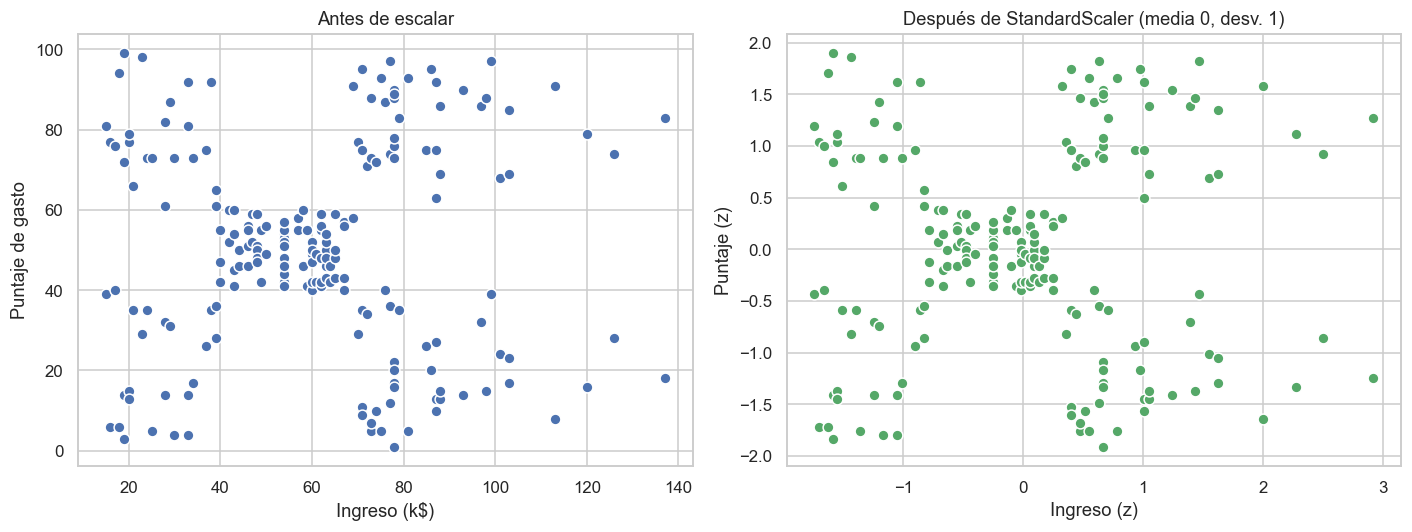

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X[:, 0], X[:, 1], c="#4C72B0", edgecolor="white", s=50)
axes[0].set_title("Antes de escalar"); axes[0].set_xlabel("Ingreso (k$)"); axes[0].set_ylabel("Puntaje de gasto")
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c="#55A868", edgecolor="white", s=50)
axes[1].set_title("Después de StandardScaler (media 0, desv. 1)"); axes[1].set_xlabel("Ingreso (z)"); axes[1].set_ylabel("Puntaje (z)")
plt.tight_layout(); plt.show()

**❓ ¿Por qué es necesario escalar las variables en el algoritmo K-Means?**

K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**:

$$d(x, c) = \sqrt{\sum_j (x_j - c_j)^2}$$

Si las variables tienen escalas o rangos distintos, la que tenga números más grandes **domina el cálculo de la distancia** y el algoritmo prácticamente ignora las demás. Por ejemplo, si se agrega la Edad (18–70) junto al Ingreso (15–137), o si el ingreso estuviera en dólares (15 000–137 000) en lugar de miles, el ingreso decidiría casi solo a qué cluster pertenece cada cliente.

Con `StandardScaler` todas las variables quedan con **media 0 y desviación estándar 1**, así cada una aporta en igual proporción a la distancia. Además, hace que la inercia y el coeficiente de silueta sean comparables y que el algoritmo converja de forma más estable. En este dataset, ingreso y puntaje tienen rangos parecidos, pero escalar sigue siendo la buena práctica porque garantiza que el resultado no dependa de las unidades de medida.

---
# Parte 3 – Método del Codo
Se entrena K-Means para K = 1 … 10 y se registra la **inercia (WCSS)**: la suma de las distancias al cuadrado de cada punto a su centroide.

$$WCSS = \sum_{k=1}^{K} \sum_{x \in C_k} \lVert x - \mu_k \rVert^2$$

In [11]:
K_RANGE = range(1, 11)
inercias = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

tabla_codo = pd.DataFrame({"K": list(K_RANGE), "Inercia (WCSS)": np.round(inercias, 2)})
tabla_codo["Reducción %"] = (-tabla_codo["Inercia (WCSS)"].pct_change() * 100).round(1)
tabla_codo

,K,Inercia (WCSS),Reducción %
0,1,400.00,NaN
1,2,269.69,32.6
2,3,157.70,41.5
3,4,108.92,30.9
4,5,65.57,39.8
5,6,55.06,16.0
6,7,44.86,18.5
7,8,37.23,17.0
8,9,32.39,13.0
9,10,29.98,7.4


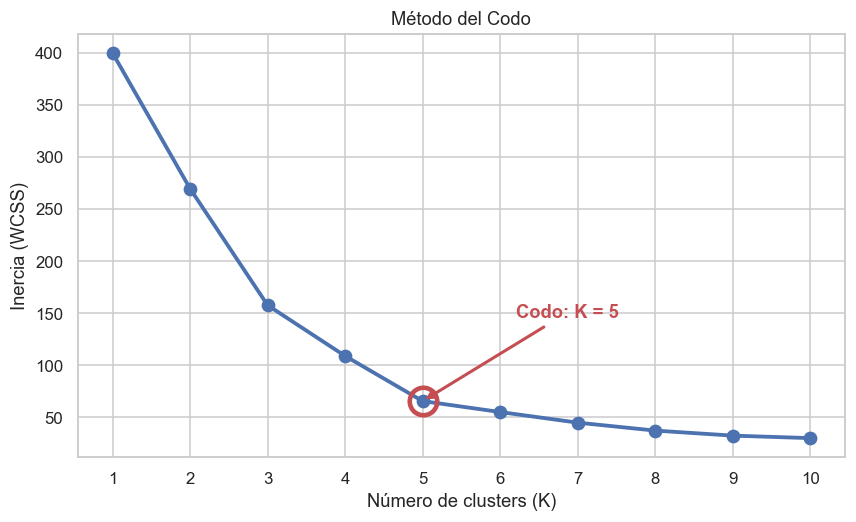

In [12]:
K_OPT = 5
plt.figure(figsize=(9, 5))
plt.plot(list(K_RANGE), inercias, "o-", color="#4C72B0", lw=2.5, ms=8)
plt.plot(K_OPT, inercias[K_OPT - 1], "o", ms=18, mfc="none", mec="#C44E52", mew=3)
plt.annotate(f"Codo: K = {K_OPT}", xy=(K_OPT, inercias[K_OPT - 1]), xytext=(K_OPT + 1.2, inercias[K_OPT - 1] + 80),
             arrowprops=dict(arrowstyle="->", color="#C44E52", lw=2), fontsize=12, color="#C44E52", weight="bold")
plt.xticks(list(K_RANGE)); plt.xlabel("Número de clusters (K)"); plt.ylabel("Inercia (WCSS)")
plt.title("Método del Codo"); plt.show()

**❓ ¿Por qué valores cercanos a cero indican mejor ajuste?**

La inercia (WCSS) mide qué tan **lejos** están los puntos de su propio centroide. Si es cercana a cero, los puntos están muy pegados a su centro: los clusters son **compactos y homogéneos**, que es justamente lo que se busca en una segmentación (clientes parecidos dentro de un mismo grupo).

**Precaución:** la inercia siempre baja al aumentar K, y llega exactamente a 0 cuando K = número de observaciones (cada cliente sería su propio cluster). Eso no es un buen modelo, es sobreajuste y no sirve para el negocio. Por eso no se busca el mínimo absoluto, sino el punto donde **agregar más clusters deja de reducir la inercia de forma importante**: el codo.

**❓ ¿Cómo se identifica el punto óptimo de K?**

Se busca el **"codo"** de la curva: el punto donde la pendiente cambia bruscamente y la curva pasa de caer rápido a caer lento.

En la tabla se ve que:
- De K=1 a K=5 la inercia baja fuertemente (400 → 65.6), con reducciones de entre 31 % y 42 % por cada K extra.
- A partir de K=5 las reducciones se vuelven pequeñas (K=6 solo reduce un 16 %, y luego aún menos).

Por lo tanto el codo está en **K = 5**: es el punto con mejor equilibrio entre compactar los grupos y mantener un número de segmentos manejable.

---
# Parte 4 – Coeficiente de Silueta
Para cada punto *i*: **a(i)** = distancia media a los puntos de su propio cluster; **b(i)** = distancia media al cluster vecino más cercano.

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}} \in [-1, 1]$$

In [13]:
siluetas = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    siluetas[k] = silhouette_score(X_scaled, labels)

tabla_sil = pd.DataFrame({"K": siluetas.keys(), "Silueta": np.round(list(siluetas.values()), 4)})
k_best = max(siluetas, key=siluetas.get)
print(f"Mejor K según silueta: {k_best} (s = {siluetas[k_best]:.4f})")
tabla_sil

Mejor K según silueta: 5 (s = 0.5547)


,K,Silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


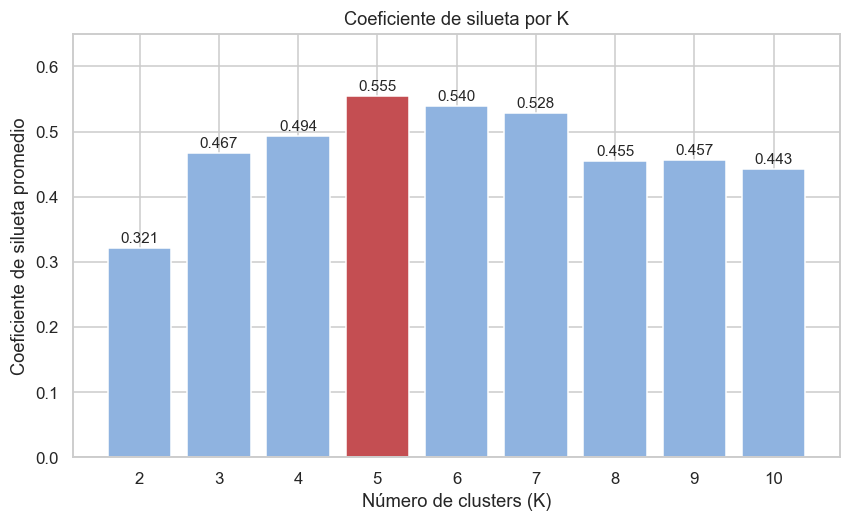

In [14]:
plt.figure(figsize=(9, 5))
colores = ["#C44E52" if k == k_best else "#8fb3e0" for k in siluetas]
plt.bar(list(siluetas.keys()), list(siluetas.values()), color=colores, edgecolor="white")
for k, s in siluetas.items():
    plt.text(k, s + 0.008, f"{s:.3f}", ha="center", fontsize=10)
plt.xticks(list(siluetas.keys())); plt.xlabel("Número de clusters (K)"); plt.ylabel("Coeficiente de silueta promedio")
plt.title("Coeficiente de silueta por K"); plt.ylim(0, 0.65); plt.show()

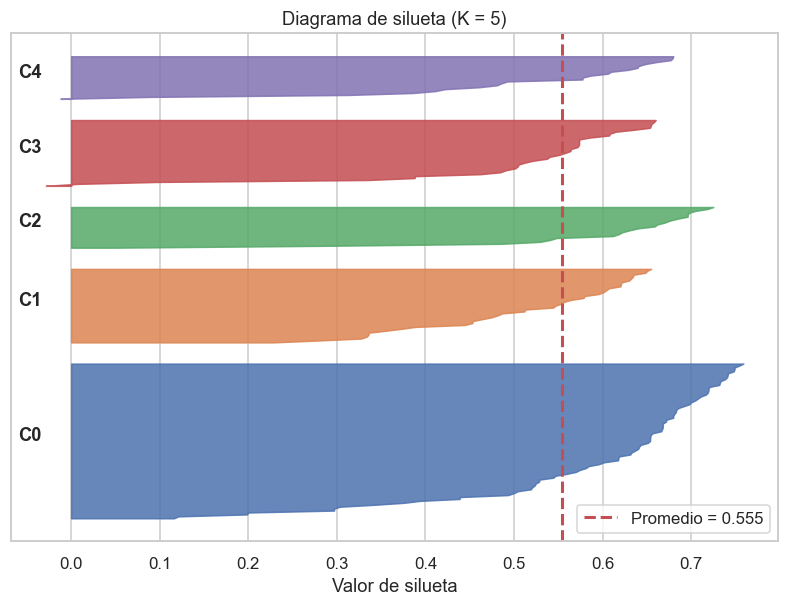

Puntos con silueta negativa: 2


In [15]:
# Diagrama de silueta detallado para K óptimo
labels_k = KMeans(n_clusters=K_OPT, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
sil_vals = silhouette_samples(X_scaled, labels_k)
fig, ax = plt.subplots(figsize=(9, 6)); y_low = 10
pal = sns.color_palette("deep", K_OPT)
for c in range(K_OPT):
    v = np.sort(sil_vals[labels_k == c]); y_up = y_low + len(v)
    ax.fill_betweenx(np.arange(y_low, y_up), 0, v, color=pal[c], alpha=.85)
    ax.text(-0.06, y_low + len(v) / 2, f"C{c}", weight="bold"); y_low = y_up + 10
ax.axvline(sil_vals.mean(), color="#C44E52", ls="--", lw=2, label=f"Promedio = {sil_vals.mean():.3f}")
ax.set_xlabel("Valor de silueta"); ax.set_yticks([]); ax.set_title(f"Diagrama de silueta (K = {K_OPT})"); ax.legend()
plt.show()
print("Puntos con silueta negativa:", (sil_vals < 0).sum())

**❓ ¿Qué mide el coeficiente de silueta?**

Mide **qué tan bien asignado** está cada punto a su cluster, comparando dos cosas: su **cohesión** (qué tan cerca está de los miembros de su propio grupo, *a(i)*) y su **separación** (qué tan lejos está del grupo vecino más cercano, *b(i)*). El promedio de todos los puntos resume la calidad global del agrupamiento. Va de -1 a 1 y, a diferencia de la inercia, **no mejora automáticamente al aumentar K**, por eso sirve para elegir el número de clusters.

**❓ ¿Qué significa un valor cercano a 1?**

Que *a(i)* es mucho menor que *b(i)*: el punto está muy cerca de los miembros de su cluster y muy lejos del cluster vecino. Es decir, la asignación es **correcta y los grupos están bien definidos y separados**. Como referencia práctica: > 0.7 estructura fuerte, 0.5–0.7 estructura razonable, 0.25–0.5 estructura débil.

**❓ ¿Qué implica un valor cercano a 0 o negativo?**

- **Cercano a 0:** *a(i)* ≈ *b(i)*, el punto está en la **frontera entre dos clusters**; los grupos se superponen y la asignación es ambigua.
- **Negativo:** *a(i)* > *b(i)*, el punto está más cerca de otro cluster que del suyo, es decir, **probablemente está mal asignado**. Si muchos puntos son negativos, el valor de K o las variables elegidas no son adecuados.

En nuestro modelo con K = 5 solo 2 de 200 clientes tienen silueta negativa (puntos de frontera), lo que confirma una buena asignación.

**❓ ¿Coincide el valor óptimo de K con el método del codo? Justifique.**

**Sí, coinciden en K = 5.**

- **Método del codo:** el cambio de pendiente más marcado está en K = 5; después las reducciones de inercia son marginales.
- **Silueta:** el máximo se alcanza en K = 5 (**≈ 0.555**), por encima de K = 4 (0.494) y K = 6 (0.540).

Que dos criterios distintos (uno basado solo en compactación y otro en compactación + separación) lleguen al mismo valor da **alta confianza** en la elección. Además, K = 5 coincide con las cinco nubes que se veían en el diagrama de dispersión de la Parte 1 y es un número de segmentos fácil de gestionar para el área de marketing.

---
# Parte 5 – Modelo K-Means (K = 5)

In [16]:
kmeans = KMeans(n_clusters=K_OPT, init="k-means++", n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(f"Inercia final: {kmeans.inertia_:.2f}")
print(f"Silueta final: {silhouette_score(X_scaled, df['Cluster']):.4f}")
print(f"Iteraciones hasta converger: {kmeans.n_iter_}")
df.head(10)

Inercia final: 65.57
Silueta final: 0.5547
Iteraciones hasta converger: 4


,CustomerID,Genero,Edad,Ingreso_Anual_k,Puntaje_Gasto,Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


In [17]:
# Centroides en escala estandarizada y en unidades originales
centroides_esc = pd.DataFrame(kmeans.cluster_centers_, columns=[f + " (z)" for f in FEATURES])
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES).round(1)
centroides.index.name = "Cluster"
pd.concat([centroides, centroides_esc.round(3)], axis=1)

,Ingreso_Anual_k,Puntaje_Gasto,Ingreso_Anual_k (z),Puntaje_Gasto (z)
0,55.3,49.5,-0.201,-0.026
1,86.5,82.1,0.992,1.240
2,25.7,79.4,-1.330,1.132
3,88.2,17.1,1.055,-1.284
4,26.3,20.9,-1.308,-1.137


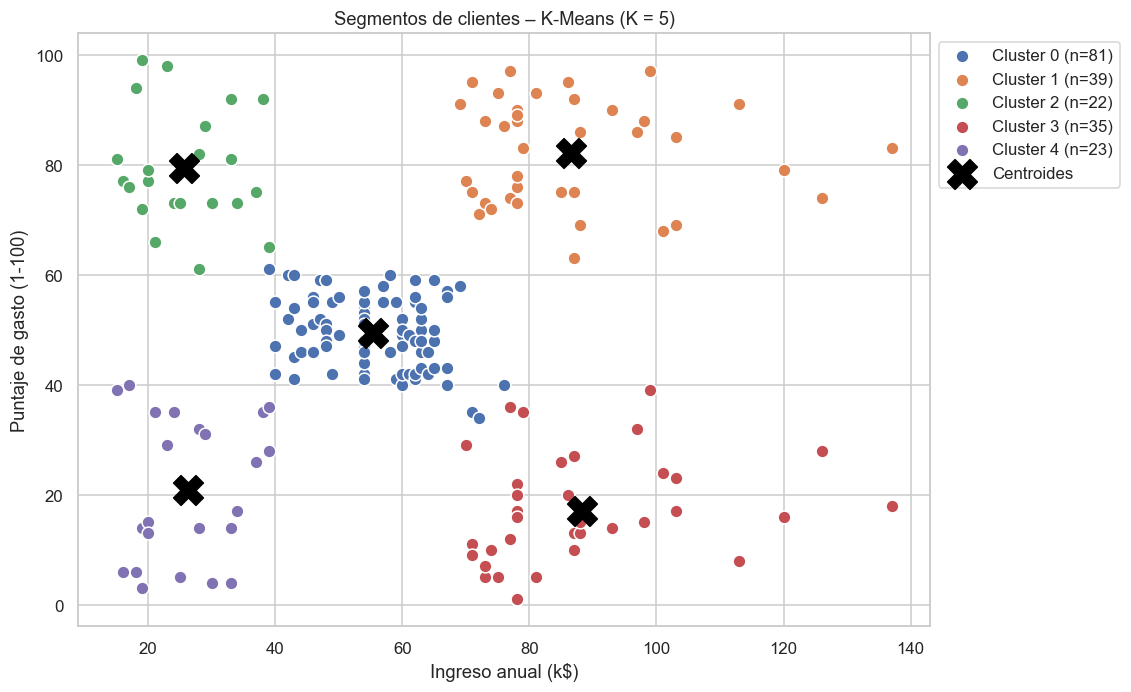

In [18]:
pal = sns.color_palette("deep", K_OPT)
plt.figure(figsize=(10, 7))
for c in range(K_OPT):
    sub = df[df["Cluster"] == c]
    plt.scatter(sub["Ingreso_Anual_k"], sub["Puntaje_Gasto"], s=70, color=pal[c], edgecolor="white", label=f"Cluster {c} (n={len(sub)})")
plt.scatter(centroides["Ingreso_Anual_k"], centroides["Puntaje_Gasto"], s=380, c="black", marker="X", label="Centroides")
plt.xlabel("Ingreso anual (k$)"); plt.ylabel("Puntaje de gasto (1-100)")
plt.title("Segmentos de clientes – K-Means (K = 5)"); plt.legend(loc="upper left", bbox_to_anchor=(1, 1)); plt.show()

In [19]:
perfil = df.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Edad_media=("Edad", "mean"),
    Ingreso_medio=("Ingreso_Anual_k", "mean"),
    Gasto_medio=("Puntaje_Gasto", "mean"),
    Pct_mujeres=("Genero", lambda g: (g == "Female").mean() * 100),
).round(1)
perfil["% del total"] = (perfil["Clientes"] / len(df) * 100).round(1)
perfil

,Clientes,Edad_media,Ingreso_medio,Gasto_medio,Pct_mujeres,% del total
Cluster,,,,,,
0,81,42.7,55.3,49.5,59.3,40.5
1,39,32.7,86.5,82.1,53.8,19.5
2,22,25.3,25.7,79.4,59.1,11.0
3,35,41.1,88.2,17.1,45.7,17.5
4,23,45.2,26.3,20.9,60.9,11.5


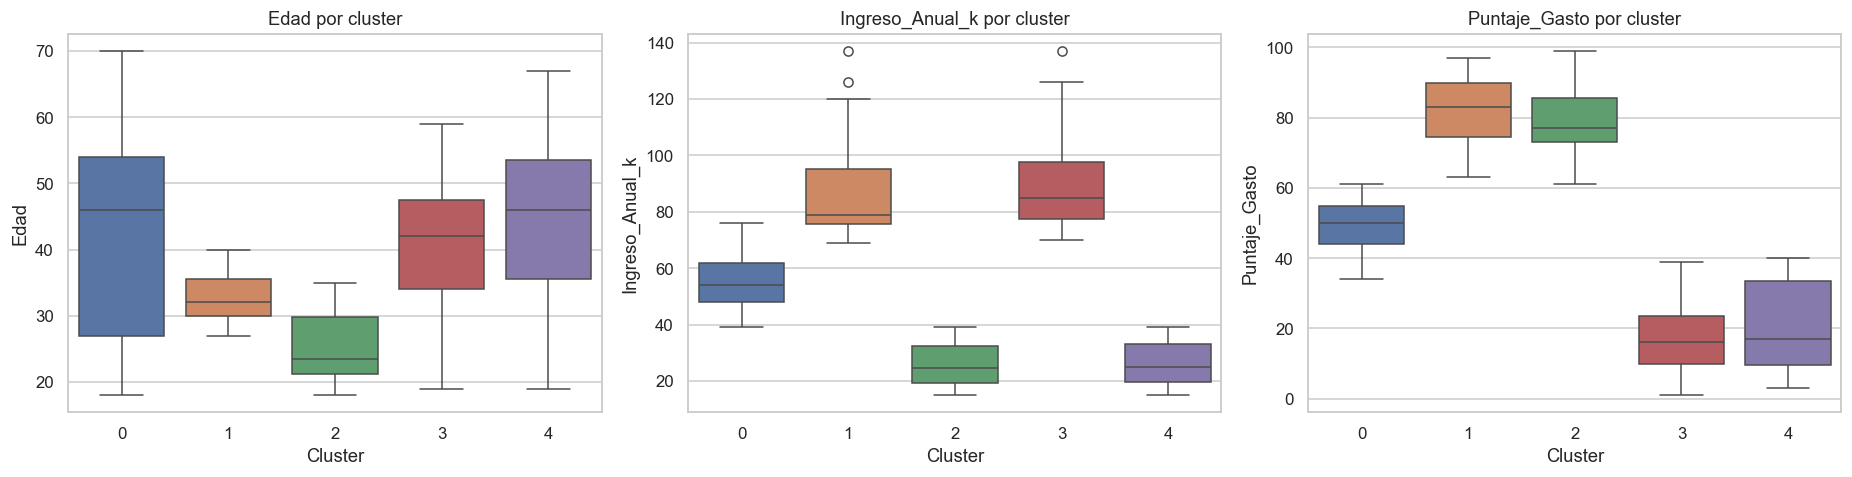

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["Edad", "Ingreso_Anual_k", "Puntaje_Gasto"]):
    sns.boxplot(data=df, x="Cluster", y=col, palette=pal, ax=ax); ax.set_title(f"{col} por cluster")
plt.tight_layout(); plt.show()

**❓ ¿Qué representa cada cluster?**

Cada cluster es un **grupo de clientes con un comportamiento de ingreso y gasto similar**, y su centroide es el "cliente típico" de ese grupo. A partir de los centroides (en unidades originales):

| Cluster | Ingreso medio | Gasto medio | Edad media | Lectura |
|---|---|---|---|---|
| 0 | ~55 k\$ | ~50 | ~43 | Ingreso medio, gasto medio. El grupo más grande (≈40 %). |
| 1 | ~87 k\$ | ~82 | ~33 | Ingreso alto **y** gasto alto. |
| 2 | ~26 k\$ | ~79 | ~25 | Ingreso bajo pero gasto alto (jóvenes). |
| 3 | ~88 k\$ | ~17 | ~41 | Ingreso alto pero gasto **bajo**. |
| 4 | ~26 k\$ | ~21 | ~45 | Ingreso bajo y gasto bajo. |

*(La numeración de los clusters la asigna el algoritmo y no tiene significado por sí misma; lo importante son sus centroides.)*

**❓ ¿Qué diferencias existen entre los grupos obtenidos?**

- **Por ingreso** se forman dos bloques extremos (~26 k\$ vs ~87 k\$) y uno intermedio (~55 k\$).
- **Por gasto**, dentro de cada nivel de ingreso extremo hay clientes que gastan mucho y otros que gastan poco. Esto demuestra que **tener dinero no implica gastarlo en el centro comercial** (correlación ≈ 0).
- **Por edad** (aunque no se usó para entrenar), los grupos de gasto alto son claramente más jóvenes (25–33 años) que los de gasto bajo (41–45 años), lo que coincide con la correlación negativa edad–gasto de la Parte 1.
- **Por tamaño**, el grupo medio concentra ~40 % de los clientes, mientras que los otros cuatro tienen entre 11 % y 20 % cada uno.
- **Por género**, la proporción de mujeres está entre 46 % y 61 % en todos los grupos, sin diferencias marcadas, así que el género no es lo que define los segmentos.

---
# Parte 6 – Interpretación de Negocio
Los perfiles se asignan con reglas sobre los centroides (comparados con la media de cada variable), para que la etiqueta no dependa del número que el algoritmo le dio a cada cluster.

In [21]:
ING_MED, GAS_MED = df["Ingreso_Anual_k"].mean(), df["Puntaje_Gasto"].mean()

def asignar_perfil(ingreso, gasto, margen=15):
    alto_ing, bajo_ing = ingreso > ING_MED + margen, ingreso < ING_MED - margen
    alto_gas, bajo_gas = gasto > GAS_MED + margen, gasto < GAS_MED - margen
    if alto_ing and alto_gas:  return "Clientes de alto valor"
    if alto_ing and bajo_gas:  return "Clientes con potencial"
    if bajo_ing and bajo_gas:  return "Clientes de bajo valor"
    if bajo_ing and alto_gas:  return "Clientes impulsivos"
    return "Clientes promedio"

centroides["Perfil"] = [asignar_perfil(r.Ingreso_Anual_k, r.Puntaje_Gasto) for r in centroides.itertuples()]
mapa_perfil = centroides["Perfil"].to_dict()
df["Perfil"] = df["Cluster"].map(mapa_perfil)

resumen_negocio = perfil.join(centroides["Perfil"]).set_index("Perfil", append=True)
resumen_negocio

,,Clientes,Edad_media,Ingreso_medio,Gasto_medio,Pct_mujeres,% del total
Cluster,Perfil,,,,,,
0,Clientes promedio,81,42.7,55.3,49.5,59.3,40.5
1,Clientes de alto valor,39,32.7,86.5,82.1,53.8,19.5
2,Clientes impulsivos,22,25.3,25.7,79.4,59.1,11.0
3,Clientes con potencial,35,41.1,88.2,17.1,45.7,17.5
4,Clientes de bajo valor,23,45.2,26.3,20.9,60.9,11.5


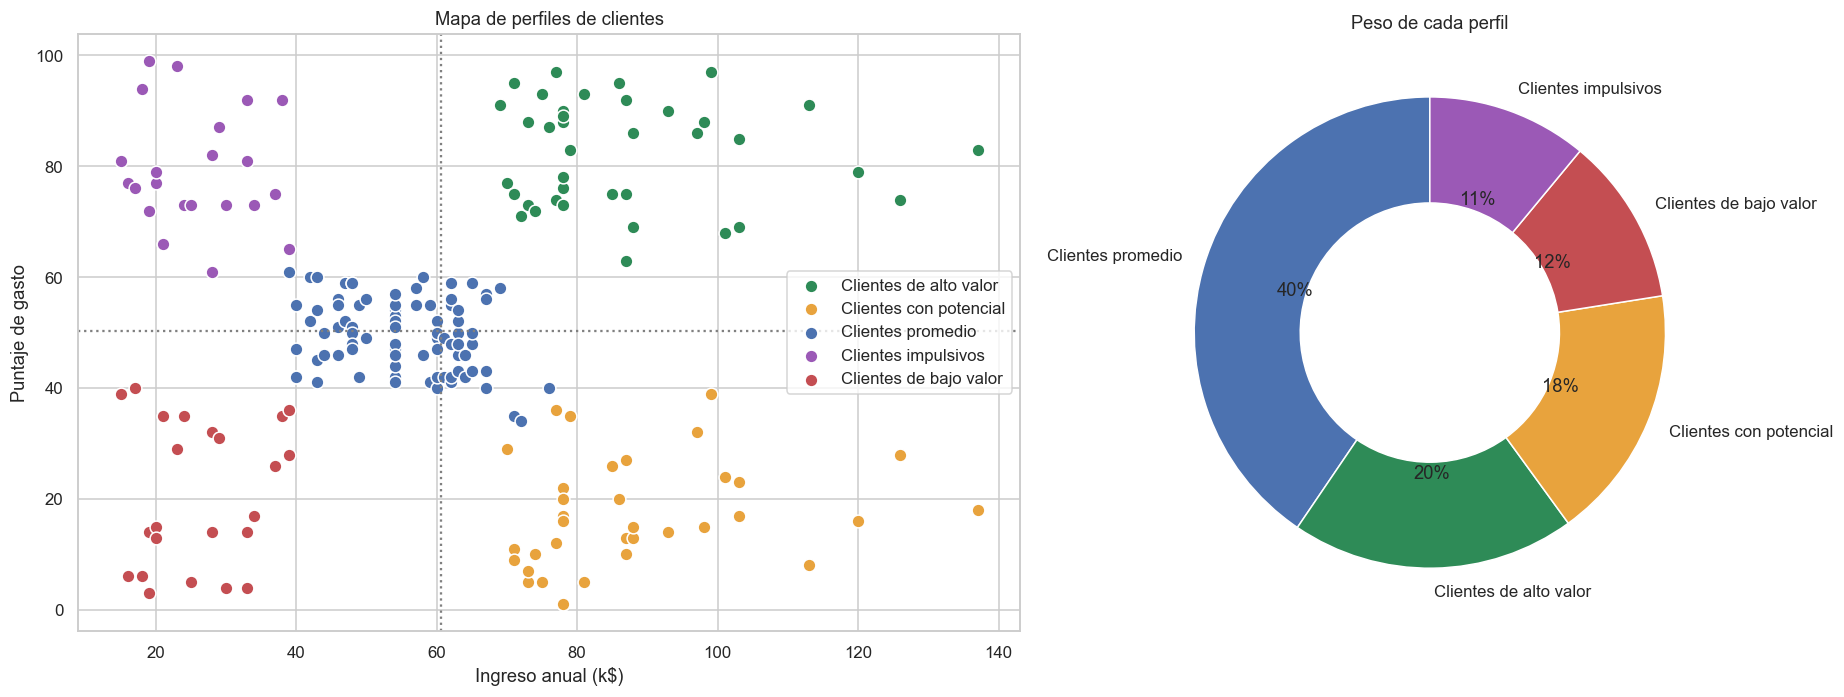

In [22]:
colores_perfil = {
    "Clientes de alto valor": "#2E8B57", "Clientes con potencial": "#E8A33D",
    "Clientes promedio": "#4C72B0", "Clientes impulsivos": "#9B59B6", "Clientes de bajo valor": "#C44E52",
}
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
for p, col in colores_perfil.items():
    sub = df[df["Perfil"] == p]
    axes[0].scatter(sub["Ingreso_Anual_k"], sub["Puntaje_Gasto"], s=70, color=col, edgecolor="white", label=p)
axes[0].axvline(ING_MED, ls=":", c="gray"); axes[0].axhline(GAS_MED, ls=":", c="gray")
axes[0].set_xlabel("Ingreso anual (k$)"); axes[0].set_ylabel("Puntaje de gasto"); axes[0].set_title("Mapa de perfiles de clientes"); axes[0].legend()
conteo = df["Perfil"].value_counts()
axes[1].pie(conteo, labels=conteo.index, autopct="%1.0f%%", colors=[colores_perfil[p] for p in conteo.index],
            wedgeprops=dict(width=.45, edgecolor="white"), startangle=90)
axes[1].set_title("Peso de cada perfil")
plt.tight_layout(); plt.show()

### Perfiles de clientes

| Perfil | Ingreso | Gasto | Edad típica | % clientes | Descripción |
|---|---|---|---|---|---|
| 🟢 **Clientes de alto valor** | Alto (~87 k\$) | Alto (~82) | ~33 | ~20 % | Tienen dinero y lo gastan. Son el núcleo de los ingresos del centro comercial. |
| 🟠 **Clientes con potencial** | Alto (~88 k\$) | Bajo (~17) | ~41 | ~18 % | Tienen alta capacidad de compra pero gastan poco aquí: compran en otro lado o no encuentran lo que buscan. |
| 🔵 **Clientes promedio** | Medio (~55 k\$) | Medio (~50) | ~43 | ~40 % | El grupo más grande, estable y predecible. |
| 🟣 **Clientes impulsivos** | Bajo (~26 k\$) | Alto (~79) | ~25 | ~11 % | Jóvenes que gastan por encima de su ingreso; sensibles a tendencias y promociones. |
| 🔴 **Clientes de bajo valor** | Bajo (~26 k\$) | Bajo (~21) | ~45 | ~11 % | Bajo ingreso y bajo gasto; compran lo necesario y son muy sensibles al precio. |

*Nota:* el taller pide cuatro perfiles (alto valor, promedio, bajo valor, con potencial). Como el modelo óptimo encontró **cinco** grupos, el quinto (ingreso bajo y gasto alto) se identifica como **"Clientes impulsivos"**, un perfil distinto que no conviene mezclar con los otros porque requiere una estrategia propia.

**❓ ¿Qué estrategias de marketing se podrían aplicar a cada grupo?**

| Perfil | Objetivo | Estrategias |
|---|---|---|
| 🟢 **Alto valor** | **Retener y fidelizar** | Programa VIP / membresía premium con beneficios exclusivos · acceso anticipado a lanzamientos y eventos privados · atención personalizada (personal shopper) · marcas premium y experiencias. Perder a uno de estos clientes cuesta mucho. |
| 🟠 **Con potencial** | **Activar y convertir** | Investigar por qué no compran (encuestas) · campañas de marcas de lujo y productos de calidad, no de descuento · experiencias (gastronomía, eventos, servicios exclusivos) · comunicación orientada a calidad, comodidad y ahorro de tiempo · ofertas de primera compra en categorías premium. |
| 🔵 **Promedio** | **Mantener y hacer crecer el ticket** | Programa de puntos por acumulación · *cross-selling* y combos · promociones de temporada (regreso a clases, Navidad) · comunicación masiva por correo y redes · incentivos para subir de nivel en el programa de fidelización. |
| 🟣 **Impulsivos** | **Capitalizar el engagement con responsabilidad** | Marketing en redes sociales e influencers · tendencias, moda y tecnología · ventas flash y *drops* limitados · opciones de pago a plazos / BNPL · gamificación y app con recompensas. Cuidar la sostenibilidad (su ingreso es bajo). |
| 🔴 **Bajo valor** | **Eficiencia, bajo costo de adquisición** | Descuentos y cupones en productos básicos · tiendas de precio bajo y outlets · días de promoción específicos · comunicación de bajo costo (SMS, redes) · no invertir mucho presupuesto por cliente. |

**❓ ¿Qué segmento representa mayor oportunidad de crecimiento?**

**Los "Clientes con potencial"** (ingreso alto, gasto bajo – ≈ 18 % de los clientes).

1. **Brecha más grande entre capacidad y consumo:** tienen un ingreso medio de ~88 k\$ (igual que los de alto valor) pero su puntaje de gasto es ~17, frente a ~82 del grupo de alto valor. Hay casi **65 puntos de gasto "sin aprovechar"** por cliente.
2. **No hay que crear demanda, solo captarla:** ya tienen el dinero; el problema es que no lo gastan en este centro comercial. Convertir aunque sea una parte los acerca al grupo más rentable.
3. **Tamaño relevante:** 35 clientes, casi el mismo número que el grupo de alto valor.

**Segunda oportunidad:** los *Clientes promedio*, porque son el 40 % de la base; pequeños aumentos en su ticket generan un impacto grande en volumen.

**Conclusión:** la estrategia recomendada es **proteger** a los clientes de alto valor, **activar** a los clientes con potencial y **hacer crecer** a los promedio, que juntos representan cerca del 78 % de los clientes.

---
### Guardar el modelo para el despliegue (Parte 7)

In [23]:
joblib.dump({"scaler": scaler, "kmeans": kmeans, "features": FEATURES, "perfiles": mapa_perfil}, "modelo_kmeans.pkl")
df.to_csv("clientes_segmentados.csv", index=False)
print("✅ Modelo guardado en modelo_kmeans.pkl")
print("✅ Datos con cluster guardados en clientes_segmentados.csv")

✅ Modelo guardado en modelo_kmeans.pkl
✅ Datos con cluster guardados en clientes_segmentados.csv


---
# Parte 7 – Despliegue con Streamlit
La aplicación está en el archivo **`app.py`**. Para ejecutarla, en la terminal (dentro de la carpeta del proyecto):

```bash
streamlit run app.py
```

Funcionalidades:
- Visualización del **método del codo** y del **coeficiente de silueta** (con selector de K).
- Visualización de los **clusters** en 2D y 3D con sus centroides y perfiles.
- Formulario para **ingresar un nuevo cliente**.
- **Clasificación automática** del cliente en su cluster, con su perfil, estrategia recomendada y distancia a cada centroide.

# Conclusiones
1. Las variables **Ingreso anual** y **Puntaje de gasto** permiten una segmentación clara de los clientes; la edad sirve para enriquecer la descripción de los perfiles.
2. Escalar con **StandardScaler** garantiza que todas las variables pesen igual en la distancia euclidiana.
3. El **método del codo** y el **coeficiente de silueta (0.555)** coinciden en **K = 5**, lo que da robustez a la elección.
4. Los cinco segmentos tienen interpretaciones de negocio claras y accionables, y el segmento **con potencial** (alto ingreso, bajo gasto) es la mayor oportunidad de crecimiento.
5. El modelo se desplegó en una aplicación interactiva de Streamlit que clasifica nuevos clientes en tiempo real.